# T03 - Greeks
### Ana Paula Moreno Haro

## Parte 1: Observación

**1. ¿Cuál opción parece más sensible a cambios en el precio de la acción?**

La opción A, porque tiene la Delta más alta (0.85). Esto significa que su prima cambia aproximadamente \$0.85 por cada \$1 que se mueve la acción.

**2. ¿Cuál opción parece más sensible a cambios en volatilidad?**

La opción C, porque tiene la Vega más alta (0.40). Al ser de largo plazo y estar fuera del dinero, casi todo su valor es valor tiempo, que depende de la volatilidad.

**3. ¿Cuál opción parece deteriorarse más rápidamente con el paso del tiempo?**

La opción A, porque tiene la Theta más negativa (-0.10) y vence en solo un mes, por lo que pierde valor más rápido que las demás.

**4. ¿Cuál opción parece tener el comportamiento más parecido al de la acción?**

La opción A, porque está muy dentro del dinero (K = 90) y su Delta es cercana a 1, por lo que se mueve casi igual que la acción.

**5. ¿Cuál opción parece depender más de que ocurra un evento importante en el futuro?**

La opción C, porque con K = 120 la acción necesita subir más de 20% para que la opción termine en el dinero. Su valor depende de que ocurra un movimiento grande antes del vencimiento.

## Parte 2: Escenarios de mercado

**Escenario A: Piensas que la acción aumentará gradualmente durante los próximos meses y no crees que cambie la volatilidad. ¿Qué opción comprarías y cuál evitarías?**

Compraría la opción B porque su plazo de 3 meses coincide con el horizonte esperado, tiene una Delta razonable (0.50) y poca Theta. Evitaría la A porque vence en un mes y un alza gradual no alcanza a compensar lo que pierde por el paso del tiempo.

**Escenario B: Dentro de dos semanas la empresa anunciará un nuevo producto. No sabes si el precio subirá o bajará, pero esperas un cambio brusco. ¿Qué opción comprarías y cuál evitarías?**

Compraría la opción B porque, al estar en el dinero, tiene la mayor Gamma y su Vega aprovecha el aumento de volatilidad antes del anuncio. Evitaría la A porque se comporta casi como la acción y perdería mucho si el precio baja.

**Escenario C: Piensas que la acción se mantendrá muy estable. ¿Qué opción comprarías y cuál evitarías?**

Evitaría la opción A porque es la que más valor pierde con el tiempo. Si tuviera que comprar, elegiría la C por tener la Theta más baja, aunque lo más conveniente sería vender opciones para ganar la Theta.

**Escenario D: Crees que va a haber una caída significativa del precio de la acción. ¿Qué opción comprarías y cuál evitarías?**

Evitaría la opción A porque con Delta de 0.85 pierde casi lo mismo que la acción y es la prima más cara. Si tuviera que comprar, elegiría la C por ser la más barata y con menor Delta, aunque lo ideal sería comprar puts o vender la A.

**Escenario E: Crees que el mercado está subestimando la incertidumbre futura. ¿Qué opción comprarías y cuál evitarías?**

Compraría la opción C porque tiene la Vega más alta y es la que más gana si la volatilidad sube. Evitaría la A porque casi no reacciona a la volatilidad y tiene la Theta más alta.


TABLA 1: Aproximación con Greeks
       Mes  Precio Volatilidad dS dsigma (%)  Valor aprox (Greeks)
      Mayo     100         20%  -          -                6.8887
     Junio     102         25%  2        5.0                8.8695
     Julio     101         30% -1        5.0                9.0161
    Agosto     105         28%  4       -2.0               10.3867
Septiembre     103         22% -2       -6.0                6.8813
   Octubre     110         20%  7       -2.0               10.4964

Aporte de cada Greek al cambio mensual
       Mes  Delta*dS  0.5*Gamma*dS^2  Vega*dsigma  Theta*dt
     Junio    1.1954          0.0547       1.4070   -0.6763
     Julio   -0.5977          0.0137       1.4070   -0.6763
    Agosto    2.3908          0.2189      -0.5628   -0.6763
Septiembre   -1.1954          0.0547      -1.6884   -0.6763
   Octubre    4.1839          0.6703      -0.5628   -0.6763

TABLA 2: Valor Black-Scholes (10,000 escenarios)
       Mes  Precio Volatilidad Tiempo restante 

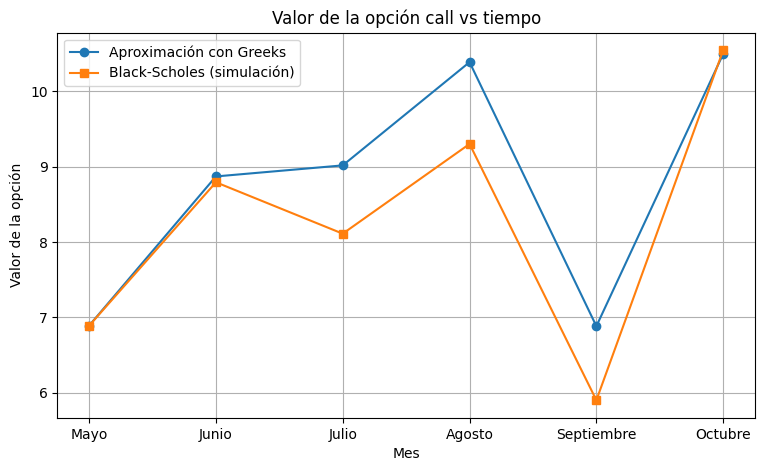

In [2]:
# Parte 3: Simulación

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

np.random.seed(42)


meses   = ["Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre"]
precios = [100, 102, 101, 105, 103, 110]
vols    = [0.20, 0.25, 0.30, 0.28, 0.22, 0.20]
tiempos = [6/12, 5/12, 4/12, 3/12, 2/12, 1/12]

r  = 0.05
K  = 100
V0 = 6.8887


delta = 0.5977
gamma = 0.02736
vega  = 0.2814
theta = -8.116
dt    = 1/12


# 1) Valor aproximado con Greeks

V_greeks = [V0]
lista_dS = ["-"]
lista_dsig = ["-"]

aporte_delta = []
aporte_gamma = []
aporte_vega  = []
aporte_theta = []

for i in range(1, len(meses)):
    dS   = precios[i] - precios[i-1]
    dsig = (vols[i] - vols[i-1]) * 100

    t_delta = delta * dS
    t_gamma = 0.5 * gamma * dS**2
    t_vega  = vega * dsig
    t_theta = theta * dt

    V = V_greeks[i-1] + t_delta + t_gamma + t_vega + t_theta

    V_greeks.append(V)
    lista_dS.append(dS)
    lista_dsig.append(round(dsig, 2))
    aporte_delta.append(t_delta)
    aporte_gamma.append(t_gamma)
    aporte_vega.append(t_vega)
    aporte_theta.append(t_theta)

tabla1 = pd.DataFrame({
    "Mes": meses,
    "Precio": precios,
    "Volatilidad": [f"{v:.0%}" for v in vols],
    "dS": lista_dS,
    "dsigma (%)": lista_dsig,
    "Valor aprox (Greeks)": np.round(V_greeks, 4)
})
print("\nTABLA 1: Aproximación con Greeks")
print(tabla1.to_string(index=False))

tabla_aportes = pd.DataFrame({
    "Mes": meses[1:],
    "Delta*dS": np.round(aporte_delta, 4),
    "0.5*Gamma*dS^2": np.round(aporte_gamma, 4),
    "Vega*dsigma": np.round(aporte_vega, 4),
    "Theta*dt": np.round(aporte_theta, 4)
})
print("\nAporte de cada Greek al cambio mensual")
print(tabla_aportes.to_string(index=False))


# 2) Valor de la call con simulación (10,000 escenarios)

def call_montecarlo(S, sigma, T, n=10000):
    Z = np.random.normal(0, 1, n)
    ST = S * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    payoff = np.maximum(ST - K, 0)
    return np.exp(-r * T) * np.mean(payoff)

def call_bs(S, sigma, T):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

V_mc = []
V_formula = []
for i in range(len(meses)):
    V_mc.append(call_montecarlo(precios[i], vols[i], tiempos[i]))
    V_formula.append(call_bs(precios[i], vols[i], tiempos[i]))

tabla2 = pd.DataFrame({
    "Mes": meses,
    "Precio": precios,
    "Volatilidad": [f"{v:.0%}" for v in vols],
    "Tiempo restante": ["6/12", "5/12", "4/12", "3/12", "2/12", "1/12"],
    "Valor BS (simulado)": np.round(V_mc, 4),
    "Valor BS (fórmula)": np.round(V_formula, 4)
})
print("\nTABLA 2: Valor Black-Scholes (10,000 escenarios)")
print(tabla2.to_string(index=False))

# 3) Comparación

error = [abs(V_greeks[i] - V_mc[i]) for i in range(len(meses))]

tabla3 = pd.DataFrame({
    "Mes": meses,
    "Greeks": ["-"] + list(np.round(V_greeks[1:], 4)),
    "Black-Scholes": np.round(V_mc, 4),
    "Error absoluto": ["-"] + list(np.round(error[1:], 4))
})
print("\nTABLA 3: Comparación")
print(tabla3.to_string(index=False))

mes_max = np.argmax(error[1:]) + 1
print(f"\nEl error más grande fue en {meses[mes_max]}: {error[mes_max]:.4f}")

# 4) Gráfica

plt.figure(figsize=(9, 5))
plt.plot(meses, V_greeks, marker="o", label="Aproximación con Greeks")
plt.plot(meses, V_mc, marker="s", label="Black-Scholes (simulación)")
plt.title("Valor de la opción call vs tiempo")
plt.xlabel("Mes")
plt.ylabel("Valor de la opción")
plt.legend()
plt.grid(True)
plt.show()